# Predicting Tomorrow's Rainfall in Sri Lanka with Ensemble Learning
### Bagging vs Boosting vs Stacking, and hybrid models (Random Forest + ARMA, Random Forest + ANN)

**Module:** Machine Learning - Ensemble Learning Assignment
**Student:** Attanayake AMSL (224016H)

---

**Question:** *Given today's weather at a Sri Lankan city, how much rain (mm) will fall there tomorrow?*

Why this matters locally:
- **Agriculture** - paddy farmers plan Yala and Maha cultivation around rain; tea estates in Nuwara Eliya / Badulla depend on it.
- **Floods and landslides** - Ratnapura, Colombo (Kelani river) and Galle flood almost every South-West monsoon; the east floods in the North-East monsoon.
- **Water and power** - reservoir and hydro-power planning (Mahaweli) depend on rainfall.

**Contents**
1. Data (real Sri Lankan weather, 12 cities, 10 years)
2. Exploratory analysis - monsoons, wet zone vs dry zone
3. Feature engineering
4. Baselines
5. Bagging models
6. Boosting models
7. Neural network (ANN)
8. Time-series model (ARMA) and the RF + ARMA hybrid
9. RF + ANN hybrid and Stacking
10. Comparison of results
11. Interpretation - *why* each model behaves the way it does
12. Saving the models for the dashboard
13. Conclusion and limitations

In [1]:
import warnings, time, json
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
                              GradientBoostingRegressor, AdaBoostRegressor, StackingRegressor)
from sklearn.linear_model import Ridge, RidgeCV, LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, f1_score, accuracy_score
from sklearn.inspection import permutation_importance

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (10, 4)})

ROOT = Path(".")
(ROOT / "models").mkdir(exist_ok=True)
(ROOT / "results").mkdir(exist_ok=True)
(ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)

## 1. Data

**Source:** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), which serves the
**ECMWF ERA5 reanalysis** - real weather observations (weather stations, satellites, radiosondes, ships) combined into a
consistent global grid. It is the same data used by climate researchers, and it lets us get a complete, gap-free daily
record for any Sri Lankan city. The download script is `data/fetch_weather.py`.

- **12 cities** covering all three climatic zones of Sri Lanka
  - *Wet zone:* Colombo, Galle, Ratnapura, Kandy, Nuwara Eliya
  - *Intermediate zone:* Kurunegala, Badulla
  - *Dry zone:* Anuradhapura, Jaffna, Trincomalee, Batticaloa, Hambantota
- **Daily data, 1 Jan 2015-31 Dec 2024** (10 years → 12 × 3,653 = 43,836 rows)
- **Variables:** max/min/mean temperature, rainfall, rain hours, wind speed / gusts / direction, solar radiation,
  evapotranspiration, relative humidity, sea-level pressure, cloud cover, dew point.

In [2]:
raw = pd.read_csv("data/raw/sri_lanka_weather_daily.csv", parse_dates=["date"])
raw = raw.rename(columns={
    "temperature_2m_max": "temp_max", "temperature_2m_min": "temp_min", "temperature_2m_mean": "temp_mean",
    "precipitation_sum": "rain", "precipitation_hours": "rain_hours",
    "wind_speed_10m_max": "wind_max", "wind_gusts_10m_max": "gust_max", "wind_direction_10m_dominant": "wind_dir",
    "shortwave_radiation_sum": "radiation", "et0_fao_evapotranspiration": "et0",
    "relative_humidity_2m_mean": "humidity", "pressure_msl_mean": "pressure",
    "cloud_cover_mean": "cloud_cover", "dew_point_2m_mean": "dew_point"})
print(raw.shape)
raw.head()

(43836, 20)


,city,zone,latitude,longitude,elevation,date,temp_max,temp_min,temp_mean,rain,rain_hours,wind_max,gust_max,wind_dir,radiation,et0,humidity,pressure,cloud_cover,dew_point
0,Colombo,Wet,6.9271,79.8612,9.0,2015-01-01,28.4,23.2,25.8,1.4,7.0,11.4,27.4,210,18.30,3.51,88,1009.8,39,23.6
1,Colombo,Wet,6.9271,79.8612,9.0,2015-01-02,28.8,22.9,25.5,0.0,0.0,9.6,22.0,282,19.63,3.95,82,1011.8,28,22.1
2,Colombo,Wet,6.9271,79.8612,9.0,2015-01-03,29.9,20.9,25.6,0.0,0.0,9.9,20.2,300,22.94,4.59,81,1012.3,58,21.9
3,Colombo,Wet,6.9271,79.8612,9.0,2015-01-04,29.8,23.2,26.1,0.0,0.0,8.8,20.9,331,18.36,3.78,82,1011.8,37,22.6
4,Colombo,Wet,6.9271,79.8612,9.0,2015-01-05,29.6,23.0,26.4,0.4,2.0,7.9,19.4,6,19.99,4.06,83,1011.0,32,23.1


In [3]:
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0] if raw.isna().sum().sum() else "none")
print("\nRows per city:")
print(raw.groupby("city").size())
raw.describe().T.round(2)

Missing values per column:
none

Rows per city:
city
Anuradhapura    3653
Badulla         3653
Batticaloa      3653
Colombo         3653
Galle           3653
Hambantota      3653
Jaffna          3653
Kandy           3653
Kurunegala      3653
Nuwara Eliya    3653
Ratnapura       3653
Trincomalee     3653
dtype: int64


,count,mean,min,25%,50%,75%,max,std
latitude,43836.0,7.3999,6.0535,6.866025,7.142,7.8761,9.6615,1.001303
longitude,43836.0,80.646792,79.8612,80.328775,80.5187,81.070875,81.6747,0.514275
elevation,43836.0,278.166667,3.0,8.75,21.5,217.75,1888.0,528.124513
date,43836,2020-01-01 00:00:00,2015-01-01 00:00:00,2017-07-02 00:00:00,2020-01-01 00:00:00,2022-07-02 00:00:00,2024-12-31 00:00:00,NaN
temp_max,43836.0,29.128294,14.7,27.9,29.5,31.2,39.0,3.673148
temp_min,43836.0,22.802256,4.8,21.7,23.8,25.1,30.1,3.614655
temp_mean,43836.0,25.521964,11.3,24.8,26.2,27.5,32.4,3.382205
rain,43836.0,5.72886,0.0,0.3,2.0,7.0,265.0,10.312351
rain_hours,43836.0,7.900766,0.0,2.0,6.0,12.0,24.0,6.967962
wind_max,43836.0,16.539358,2.5,11.3,15.8,20.7,46.9,6.733715


In [4]:
city_info = raw.groupby("city")[["zone", "latitude", "longitude", "elevation"]].first()
city_info["avg_annual_rain_mm"] = (raw.groupby("city")["rain"].sum() / 10).round(0)
city_info["rainy_days_pct"] = (raw.groupby("city")["rain"].apply(lambda s: (s >= 1).mean() * 100)).round(1)
city_info.sort_values("avg_annual_rain_mm", ascending=False)

,zone,latitude,longitude,elevation,avg_annual_rain_mm,rainy_days_pct
city,,,,,,
Ratnapura,Wet,6.6828,80.3992,34.0,3954.0,82.9
Galle,Wet,6.0535,80.2210,3.0,2980.0,83.5
Colombo,Wet,6.9271,79.8612,9.0,2836.0,76.5
Badulla,Intermediate,6.9934,81.0550,661.0,2267.0,60.3
Kurunegala,Intermediate,7.4863,80.3647,124.0,2174.0,66.8
Nuwara Eliya,Wet,6.9497,80.7891,1888.0,1954.0,68.1
Kandy,Wet,7.2906,80.6337,499.0,1760.0,62.8
Batticaloa,Dry,7.7310,81.6747,4.0,1661.0,55.7
Trincomalee,Dry,8.5874,81.2152,9.0,1500.0,47.0


The table already shows the well-known Sri Lankan rainfall pattern: **Ratnapura, Galle and Colombo (wet zone)** receive
far more rain than **Jaffna, Hambantota and Anuradhapura (dry zone)**. A good model needs to know *where* it is predicting.

## 2. Exploratory data analysis

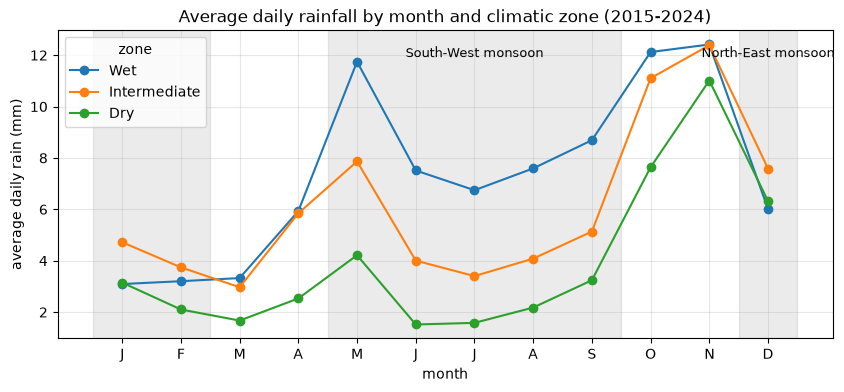

In [5]:
monthly = raw.assign(month=raw.date.dt.month).groupby(["zone", "month"])["rain"].mean().unstack(0)
ax = monthly[["Wet", "Intermediate", "Dry"]].plot(marker="o", figsize=(10, 4))
for (a, b, lab) in [(4.5, 9.5, "South-West monsoon"), (11.5, 12.5, "North-East monsoon")]:
    ax.axvspan(a, b, alpha=0.08, color="k")
    ax.text((a + b) / 2, ax.get_ylim()[1] * 0.92, lab, ha="center", fontsize=9)
ax.axvspan(0.5, 2.5, alpha=0.08, color="k")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("average daily rain (mm)"); ax.set_title("Average daily rainfall by month and climatic zone (2015-2024)")
plt.show()

**Observations**
- The **wet zone** gets rain in two peaks: the **First Inter-monsoon (Mar-Apr)** / **South-West monsoon (May-Sep)** and
  the **Second Inter-monsoon (Oct-Nov)**, which is the wettest period for most of the island.
- The **dry zone** is dry during the South-West monsoon (the central hills block the moisture - rain-shadow effect) and gets
  most of its rain in **Oct-Jan** from the Second Inter-monsoon and the **North-East monsoon**.
- So "season" and "zone" interact: the same month means opposite things in Colombo and Trincomalee. Tree ensembles can learn
  this interaction automatically; a linear model cannot.

Dry days (<1 mm): 37.4%   |  median: 2.0 mm  |  mean: 5.7 mm  |  max: 265 mm  |  skewness: 5.8


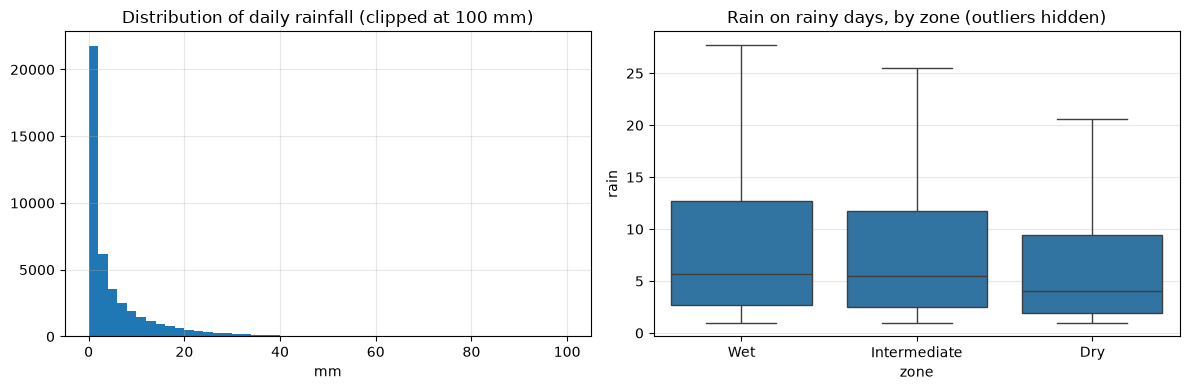

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw["rain"].clip(upper=100).hist(bins=50, ax=axes[0])
axes[0].set_title("Distribution of daily rainfall (clipped at 100 mm)"); axes[0].set_xlabel("mm")
print(f"Dry days (<1 mm): {(raw.rain < 1).mean():.1%}   |  median: {raw.rain.median():.1f} mm  |  "
      f"mean: {raw.rain.mean():.1f} mm  |  max: {raw.rain.max():.0f} mm  |  skewness: {raw.rain.skew():.1f}")
sns.boxplot(data=raw[raw.rain >= 1], x="zone", y="rain", order=["Wet", "Intermediate", "Dry"], ax=axes[1], showfliers=False)
axes[1].set_title("Rain on rainy days, by zone (outliers hidden)")
plt.tight_layout(); plt.show()

Rainfall is **very skewed**: many dry or drizzly days and a few extreme days (100+ mm). This matters for modelling:
squared-error models are pulled towards the mean and will tend to **under-predict extreme rain** - we will check this later.

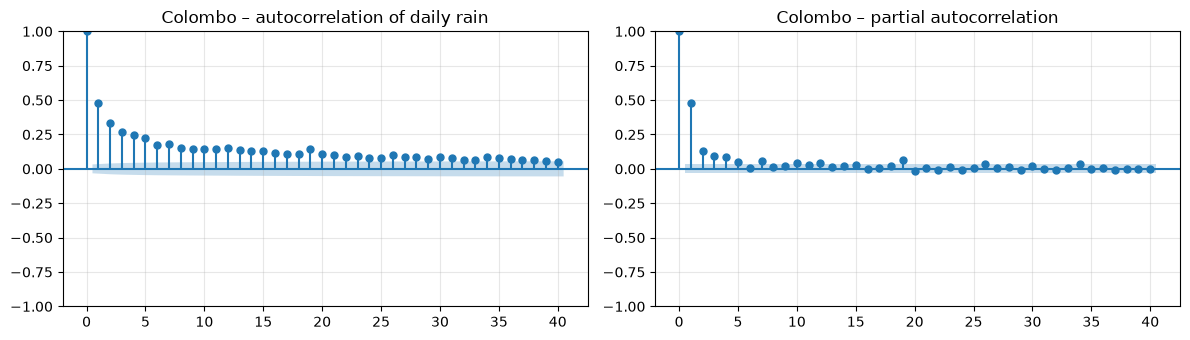

In [7]:
colombo = raw[raw.city == "Colombo"].set_index("date")["rain"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(colombo, lags=40, ax=axes[0]); axes[0].set_title("Colombo - autocorrelation of daily rain")
plot_pacf(colombo, lags=40, ax=axes[1], method="ywm"); axes[1].set_title("Colombo - partial autocorrelation")
plt.tight_layout(); plt.show()

The autocorrelation is positive and decays slowly: a rainy day tends to be followed by another rainy day (monsoon spells),
and the partial autocorrelation cuts off after a few lags. This is the classic signature for an **ARMA** model, which is why
we use **ARMA as the time-series part of a hybrid model** (Section 8).

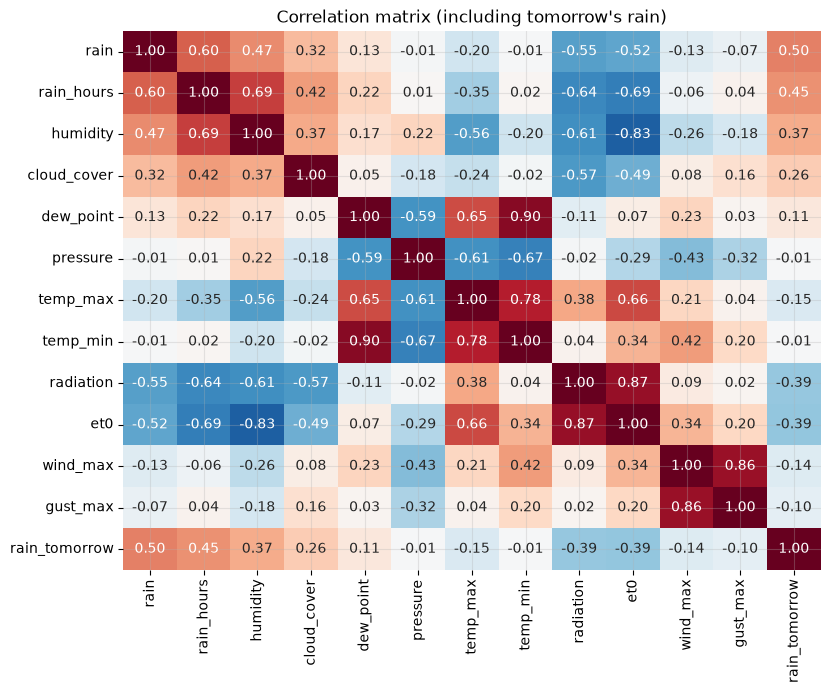

In [8]:
corr_cols = ["rain", "rain_hours", "humidity", "cloud_cover", "dew_point", "pressure", "temp_max", "temp_min",
             "radiation", "et0", "wind_max", "gust_max"]
tmp = raw.sort_values(["city", "date"]).copy()
tmp["rain_tomorrow"] = tmp.groupby("city")["rain"].shift(-1)
plt.figure(figsize=(9, 7))
sns.heatmap(tmp[corr_cols + ["rain_tomorrow"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False)
plt.title("Correlation matrix (including tomorrow's rain)"); plt.show()

Tomorrow's rain is most correlated with **today's rain, rain hours, cloud cover and humidity**, and negatively with
**radiation, evapotranspiration and max temperature** (sunny, hot days are dry days). No single variable is strongly
correlated (all |r| < 0.5), so we need models that combine many weak signals - exactly what ensembles are good at.

## 3. Feature engineering

Target: **`rain_tomorrow`** = rainfall (mm) at the same city on the next day.

Features (all available at the end of "today", so there is no information leak from the future):

| Group | Features |
|---|---|
| Today's weather | temp max/min/mean, rain, rain hours, wind, gusts, wind direction (as sin/cos), radiation, ET0, humidity, pressure, cloud cover, dew point, temp range, dew-point depression |
| Recent history | rain 1, 2, 3 and 7 days ago; rolling rain totals over 3, 7, 14 and 30 days; 3-day mean humidity & cloud cover; 1-day and 3-day pressure change |
| Season | month, day of year as sin/cos, monsoon season (SW, NE, 1st / 2nd inter-monsoon) |
| Location | latitude, longitude, elevation, climatic zone |

In [9]:
def monsoon_season(m):
    if m in (12, 1, 2): return "NE_monsoon"
    if m in (3, 4):     return "First_inter_monsoon"
    if m in (5, 6, 7, 8, 9): return "SW_monsoon"
    return "Second_inter_monsoon"   # Oct, Nov

df = raw.sort_values(["city", "date"]).reset_index(drop=True).copy()
g = df.groupby("city")

df["rain_tomorrow"] = g["rain"].shift(-1)
for lag in [1, 2, 3, 7]:
    df[f"rain_lag{lag}"] = g["rain"].shift(lag)
for w in [3, 7, 14, 30]:
    df[f"rain_sum_{w}d"] = g["rain"].transform(lambda s: s.rolling(w, min_periods=1).sum())
df["humidity_3d"] = g["humidity"].transform(lambda s: s.rolling(3, min_periods=1).mean())
df["cloud_3d"] = g["cloud_cover"].transform(lambda s: s.rolling(3, min_periods=1).mean())
df["pressure_chg_1d"] = g["pressure"].diff(1)
df["pressure_chg_3d"] = g["pressure"].diff(3)
df["temp_range"] = df["temp_max"] - df["temp_min"]
df["dewpoint_depression"] = df["temp_mean"] - df["dew_point"]
df["wind_dir_sin"] = np.sin(np.deg2rad(df["wind_dir"]))
df["wind_dir_cos"] = np.cos(np.deg2rad(df["wind_dir"]))
df["month"] = df.date.dt.month
doy = df.date.dt.dayofyear
df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
df["season"] = df["month"].map(monsoon_season)

# one-hot versions for models that need numbers only
df = pd.concat([df, pd.get_dummies(df["season"], prefix="season", dtype=int),
                pd.get_dummies(df["zone"], prefix="zone", dtype=int)], axis=1)

df = df.dropna(subset=["rain_tomorrow", "rain_lag7", "pressure_chg_3d"]).reset_index(drop=True)
print(df.shape)

(43740, 48)


In [10]:
BASE_FEATURES = [
    "temp_max", "temp_min", "temp_mean", "rain", "rain_hours", "wind_max", "gust_max", "wind_dir_sin", "wind_dir_cos",
    "radiation", "et0", "humidity", "pressure", "cloud_cover", "dew_point", "temp_range", "dewpoint_depression",
    "rain_lag1", "rain_lag2", "rain_lag3", "rain_lag7", "rain_sum_3d", "rain_sum_7d", "rain_sum_14d", "rain_sum_30d",
    "humidity_3d", "cloud_3d", "pressure_chg_1d", "pressure_chg_3d",
    "month", "doy_sin", "doy_cos", "latitude", "longitude", "elevation"]
ONEHOT = [c for c in df.columns if c.startswith("season_") or c.startswith("zone_")]
FEATURES = BASE_FEATURES + ONEHOT                       # used by sklearn / XGBoost / LightGBM / ANN
CAT_FEATURES = ["city", "zone", "season"]
CB_FEATURES = BASE_FEATURES + CAT_FEATURES              # CatBoost uses the raw categories natively
TARGET = "rain_tomorrow"
print(len(FEATURES), "numeric features;", len(CB_FEATURES), "CatBoost features")

42 numeric features; 38 CatBoost features


### Train / test split - by time, not random

Weather is a time series, so a random split would leak information (today and tomorrow would end up on different sides).
We train on **2015-2022** and test on the **unseen years 2023-2024**, which is how the model would be used in practice.

In [11]:
train = df[df.date < "2023-01-01"].sort_values(["date", "city"]).reset_index(drop=True)
test = df[df.date >= "2023-01-01"].reset_index(drop=True)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"train: {len(train):,} rows ({train.date.min().date()} → {train.date.max().date()})")
print(f"test : {len(test):,} rows ({test.date.min().date()} → {test.date.max().date()})")

train: 34,980 rows (2015-01-08 → 2022-12-31)
test : 8,760 rows (2023-01-01 → 2024-12-30)


In [12]:
RAIN_DAY = 1.0      # mm  - WMO definition of a rainy day
HEAVY = 25.0        # mm  - roughly the Met Dept 'heavy rain' level for a day

results, preds, fit_times = {}, {}, {}

def evaluate(name, y_pred, family, t=None):
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 0, None)   # rain can't be negative
    heavy = y_test.values >= HEAVY
    results[name] = {
        "family": family,
        "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred),
        "RainDay_Acc": accuracy_score(y_test >= RAIN_DAY, y_pred >= RAIN_DAY),
        "RainDay_F1": f1_score(y_test >= RAIN_DAY, y_pred >= RAIN_DAY),
        "Heavy_MAE": mean_absolute_error(y_test[heavy], y_pred[heavy]),
        "Fit_sec": t,
    }
    preds[name] = y_pred
    r = results[name]
    print(f"{name:<28} RMSE={r['RMSE']:.2f}  MAE={r['MAE']:.2f}  R2={r['R2']:.3f}  "
          f"F1(rain day)={r['RainDay_F1']:.3f}  heavy-rain MAE={r['Heavy_MAE']:.1f}" + (f"  [{t:.0f}s]" if t else ""))

def fit_eval(name, model, family, X_tr=None, X_te=None):
    X_tr = X_train if X_tr is None else X_tr
    X_te = X_test if X_te is None else X_te
    t0 = time.time(); model.fit(X_tr, y_train); t = time.time() - t0
    evaluate(name, model.predict(X_te), family, t)
    return model

## 4. Baselines

Before training ensembles we need something to beat:
- **Persistence** - "tomorrow will be like today" (a surprisingly strong forecast for weather).
- **Climatology** - the average rain for that city in that month (from the training years).
- **Linear regression** - a simple linear model on all features.
- **Single decision tree** - to show what bagging and boosting improve on.

In [13]:
evaluate("Persistence (today=tomorrow)", test["rain"], "Baseline")
clim = train.groupby(["city", "month"])[TARGET].mean().rename("clim")
evaluate("Climatology (city-month mean)", test.join(clim, on=["city", "month"])["clim"], "Baseline")
lin = fit_eval("Linear Regression", make_pipeline(StandardScaler(), LinearRegression()), "Baseline")
tree = fit_eval("Single Decision Tree", DecisionTreeRegressor(min_samples_leaf=5, random_state=SEED), "Baseline")

Persistence (today=tomorrow) RMSE=9.69  MAE=5.16  R2=0.129  F1(rain day)=0.826  heavy-rain MAE=19.8
Climatology (city-month mean) RMSE=9.49  MAE=5.51  R2=0.165  F1(rain day)=0.796  heavy-rain MAE=28.7
Linear Regression            RMSE=8.21  MAE=4.72  R2=0.374  F1(rain day)=0.825  heavy-rain MAE=22.8  [0s]


Single Decision Tree         RMSE=11.10  MAE=6.07  R2=-0.143  F1(rain day)=0.797  heavy-rain MAE=25.9  [1s]


## 5. Bagging (Bootstrap AGGregatING)

Bagging trains many **deep, independent trees in parallel**, each on a bootstrap sample of the data, and **averages** them.
Each deep tree has low bias but high variance; averaging many of them **cancels the variance**.

- **Bagging (decision trees)** - plain bagging with sklearn's `BaggingRegressor`.
- **Random Forest** - bagging + a random subset of features at every split, which makes the trees less correlated.
- **Extra Trees** - also picks the split thresholds at random → even more diversity, even lower variance.

In [14]:
bag = fit_eval("Bagging (Decision Trees)",
               BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=20), n_estimators=100,
                                n_jobs=-1, random_state=SEED), "Bagging")
rf = fit_eval("Random Forest",
              RandomForestRegressor(n_estimators=200, max_depth=16, min_samples_leaf=20, max_features=0.4,
                                    n_jobs=-1, random_state=SEED), "Bagging")
et = fit_eval("Extra Trees",
              ExtraTreesRegressor(n_estimators=200, max_depth=18, min_samples_leaf=20, max_features=0.5,
                                  n_jobs=-1, random_state=SEED), "Bagging")

Bagging (Decision Trees)     RMSE=8.19  MAE=4.68  R2=0.378  F1(rain day)=0.834  heavy-rain MAE=21.9  [9s]


Random Forest                RMSE=8.15  MAE=4.66  R2=0.384  F1(rain day)=0.833  heavy-rain MAE=22.1  [5s]


Extra Trees                  RMSE=8.18  MAE=4.63  R2=0.380  F1(rain day)=0.830  heavy-rain MAE=22.8  [2s]


**Does adding more trees really reduce error?** Below, the test RMSE of a Random Forest is computed using only the first
*k* trees. The error drops quickly and then flattens - after averaging enough trees the variance is gone and only the bias
is left. Adding more trees never makes a Random Forest overfit; it just stops helping.

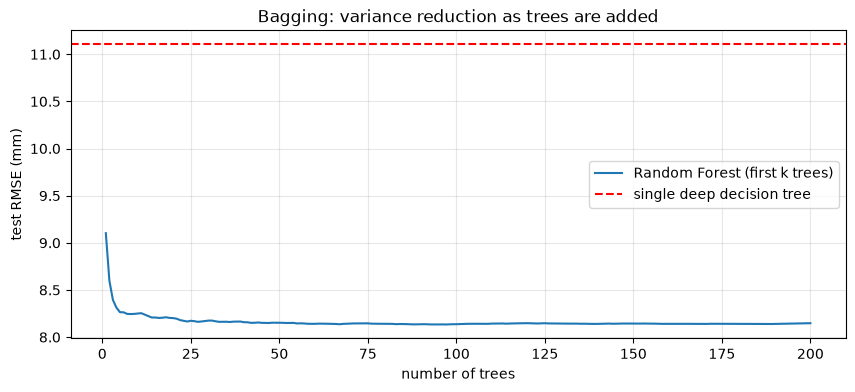

In [15]:
tree_preds = np.stack([t.predict(X_test.values) for t in rf.estimators_])
ks = np.arange(1, len(rf.estimators_) + 1)
rmse_k = [mean_squared_error(y_test, tree_preds[:k].mean(0)) ** 0.5 for k in ks]
plt.plot(ks, rmse_k, label="Random Forest (first k trees)")
plt.axhline(results["Single Decision Tree"]["RMSE"], color="r", ls="--", label="single deep decision tree")
plt.xlabel("number of trees"); plt.ylabel("test RMSE (mm)"); plt.title("Bagging: variance reduction as trees are added")
plt.legend(); plt.show()

## 6. Boosting

Boosting trains **shallow trees one after another**; each new tree is fitted to the **errors (residuals) of the trees
before it**. It therefore reduces **bias** step by step. Models compared:

- **AdaBoost** - the original boosting algorithm; re-weights badly predicted samples.
- **Gradient Boosting (sklearn)** - fits each tree to the gradient of the loss.
- **XGBoost** - gradient boosting with regularisation (L1/L2 on leaves), second-order gradients and fast histogram splits.
- **LightGBM** - leaf-wise tree growth, very fast.
- **CatBoost** - symmetric (oblivious) trees and *ordered target statistics* for categorical features - so we can give it
  the **city name, zone and season directly**, without one-hot encoding.

**How many boosting rounds?** Boosting can overfit if it runs too long, so the number of trees is chosen by
**walk-forward (time-series) validation** on the training years only: train on 2015-2019 → validate on 2020,
train on 2015-2020 → validate on 2021, train on 2015-2021 → validate on 2022. The three validation-error curves are averaged
and the round with the lowest average error is kept. One validation year alone gives a noisy answer; averaging three
years is more stable. The test years 2023-2024 are never used for tuning.

chosen boosting rounds: {'XGBoost': 83, 'LightGBM': 88, 'CatBoost': 166, 'Gradient Boosting': 96}


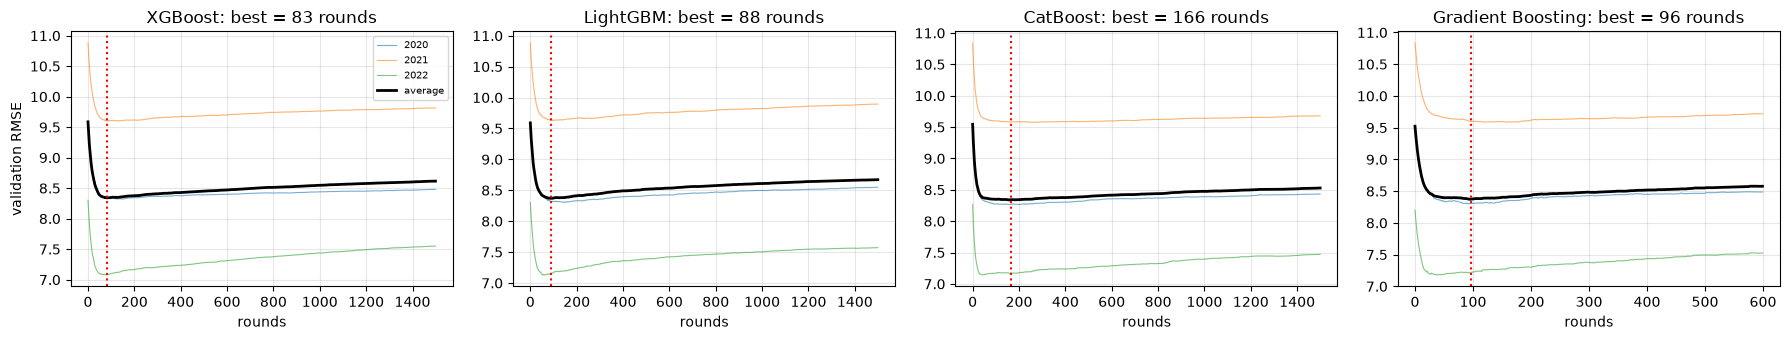

In [16]:
XGB_PARAMS = dict(max_depth=6, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, min_child_weight=10,
                  reg_lambda=2.0, n_jobs=-1, random_state=SEED)
LGB_PARAMS = dict(num_leaves=31, learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                  min_child_samples=30, random_state=SEED, verbose=-1)
CB_PARAMS = dict(depth=6, learning_rate=0.05, loss_function="RMSE", random_seed=SEED, verbose=0)
GBR_PARAMS = dict(max_depth=4, learning_rate=0.05, subsample=0.8, random_state=SEED)
MAX_ROUNDS = 1500

curves = {"XGBoost": [], "LightGBM": [], "CatBoost": [], "Gradient Boosting": []}
for year in [2020, 2021, 2022]:
    fit_m = (train.date.dt.year < year).values
    val_m = (train.date.dt.year == year).values
    Xf, yf, Xv, yv = X_train[fit_m], y_train[fit_m], X_train[val_m], y_train[val_m]

    m = xgb.XGBRegressor(n_estimators=MAX_ROUNDS, eval_metric="rmse", **XGB_PARAMS)
    m.fit(Xf, yf, eval_set=[(Xv, yv)], verbose=False)
    curves["XGBoost"].append(m.evals_result()["validation_0"]["rmse"])

    m = lgb.LGBMRegressor(n_estimators=MAX_ROUNDS, **LGB_PARAMS)
    m.fit(Xf, yf, eval_set=[(Xv, yv)], eval_metric="rmse")
    curves["LightGBM"].append(m.evals_result_["valid_0"]["rmse"])

    m = CatBoostRegressor(iterations=MAX_ROUNDS, cat_features=CAT_FEATURES, **CB_PARAMS)
    m.fit(train.loc[fit_m, CB_FEATURES], yf, eval_set=(train.loc[val_m, CB_FEATURES], yv))
    curves["CatBoost"].append(m.get_evals_result()["validation"]["RMSE"])

    m = GradientBoostingRegressor(n_estimators=600, **GBR_PARAMS).fit(Xf, yf)
    curves["Gradient Boosting"].append([mean_squared_error(yv, p) ** 0.5 for p in m.staged_predict(Xv)])

best_rounds = {k: int(np.argmin(np.mean(v, axis=0))) + 1 for k, v in curves.items()}
N_XGB, N_LGB, N_CAT, N_GBR = (best_rounds[k] for k in ["XGBoost", "LightGBM", "CatBoost", "Gradient Boosting"])
N_ADA = 100
print("chosen boosting rounds:", best_rounds)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (k, v) in zip(axes, curves.items()):
    for yr, c in zip([2020, 2021, 2022], v):
        ax.plot(c, lw=0.8, alpha=0.6, label=str(yr))
    ax.plot(np.mean(v, axis=0), "k", lw=2, label="average")
    ax.axvline(best_rounds[k], color="r", ls=":")
    ax.set_title(f"{k}: best = {best_rounds[k]} rounds"); ax.set_xlabel("rounds")
axes[0].set_ylabel("validation RMSE"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [17]:
ada = fit_eval("AdaBoost",
               AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=N_ADA, learning_rate=0.05,
                                 random_state=SEED), "Boosting")
gbr = fit_eval("Gradient Boosting", GradientBoostingRegressor(n_estimators=N_GBR, **GBR_PARAMS), "Boosting")
xgbm = fit_eval("XGBoost", xgb.XGBRegressor(n_estimators=N_XGB, **XGB_PARAMS), "Boosting")
lgbm = fit_eval("LightGBM", lgb.LGBMRegressor(n_estimators=N_LGB, **LGB_PARAMS), "Boosting")
cat = fit_eval("CatBoost", CatBoostRegressor(iterations=N_CAT, cat_features=CAT_FEATURES, **CB_PARAMS),
               "Boosting", X_tr=train[CB_FEATURES], X_te=test[CB_FEATURES])

AdaBoost                     RMSE=8.79  MAE=5.70  R2=0.284  F1(rain day)=0.792  heavy-rain MAE=18.5  [18s]


Gradient Boosting            RMSE=8.30  MAE=4.68  R2=0.361  F1(rain day)=0.823  heavy-rain MAE=22.9  [13s]


XGBoost                      RMSE=8.21  MAE=4.70  R2=0.374  F1(rain day)=0.814  heavy-rain MAE=23.1  [0s]


LightGBM                     RMSE=8.18  MAE=4.70  R2=0.380  F1(rain day)=0.792  heavy-rain MAE=22.9  [0s]


CatBoost                     RMSE=8.18  MAE=4.65  R2=0.380  F1(rain day)=0.824  heavy-rain MAE=22.4  [1s]


**Boosting rounds vs error.** Unlike bagging, boosting *can* overfit if we keep adding trees, because every tree chases the
remaining errors - including noise. The curve below tracks XGBoost's train and test RMSE as trees are added (for
illustration only - the model above used the round count chosen on the 2022 validation year).

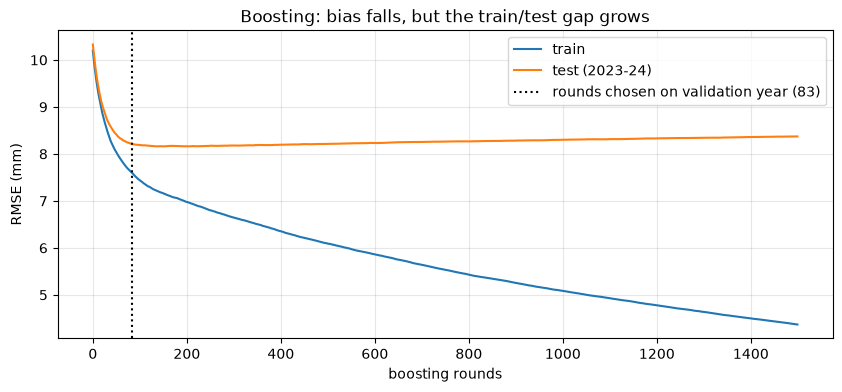

In [18]:
xgb_curve = xgb.XGBRegressor(n_estimators=1500, eval_metric="rmse", **XGB_PARAMS)
xgb_curve.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False)
ev = xgb_curve.evals_result()
plt.plot(ev["validation_0"]["rmse"], label="train")
plt.plot(ev["validation_1"]["rmse"], label="test (2023-24)")
plt.axvline(N_XGB, color="k", ls=":", label=f"rounds chosen on validation year ({N_XGB})")
plt.xlabel("boosting rounds"); plt.ylabel("RMSE (mm)"); plt.title("Boosting: bias falls, but the train/test gap grows")
plt.legend(); plt.show()

## 7. Artificial Neural Network (ANN)

A multi-layer perceptron (2 hidden layers, ReLU). Unlike trees, a neural network builds a **smooth** function of the inputs,
so it makes very different kinds of errors - which is what makes it useful in a hybrid / stacked model.
Inputs are standardised because neural networks are sensitive to feature scale.

In [19]:
ann = fit_eval("ANN (MLP)",
               make_pipeline(StandardScaler(),
                             MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3,
                                          batch_size=256, max_iter=300, early_stopping=True,
                                          n_iter_no_change=15, random_state=SEED)), "Neural network")

ANN (MLP)                    RMSE=8.28  MAE=4.60  R2=0.364  F1(rain day)=0.839  heavy-rain MAE=21.6  [2s]


## 8. Time-series model (ARMA) and the Random Forest + ARMA hybrid

**ARMA(p, q)** models today's value as a linear combination of the last *p* values and the last *q* forecast errors.
We fit one **ARMA(2,1)** per city on the training years, and then produce honest **one-step-ahead forecasts** for the test
years (each forecast only uses data up to the previous day).

**Hybrid (Zhang, 2003 style):** a time series = *linear part* + *non-linear part*.
1. ARMA captures the linear autocorrelation (rainy spells).
2. A Random Forest is trained on the **ARMA residuals** using all the weather features - it learns the non-linear part
   that ARMA cannot see (humidity, cloud, pressure, season × zone interactions).
3. Final forecast = ARMA forecast + RF residual forecast.

In [20]:
arma_pred = []
arma_models = {}
t0 = time.time()
for city, d in df.groupby("city"):
    s = raw[raw.city == city].set_index("date")["rain"].asfreq("D")
    s_train, s_rest = s[s.index < "2023-01-01"], s[s.index >= "2023-01-01"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # silence statsmodels start-parameter warnings
        res = ARIMA(s_train, order=(2, 0, 1)).fit()
        res_all = res.append(s_rest)             # keep the fitted parameters, extend the data
    arma_models[city] = res.params
    one_step = res_all.predict(start=s.index[1], end=s.index[-1])   # forecast for day t uses data up to t-1
    arma_pred.append(pd.DataFrame({"city": city, "target_date": one_step.index, "arma": one_step.values}))
arma_pred = pd.concat(arma_pred)
print(f"fitted 12 ARMA models in {time.time() - t0:.0f}s")

# rows are 'today'; the ARMA forecast we need is the one made for 'tomorrow'
for part in (train, test):
    part["target_date"] = part["date"] + pd.Timedelta(days=1)
train = train.merge(arma_pred, on=["city", "target_date"], how="left")
test = test.merge(arma_pred, on=["city", "target_date"], how="left")
print("missing ARMA forecasts:", train.arma.isna().sum(), test.arma.isna().sum())
pd.DataFrame(arma_models).T.round(3)

fitted 12 ARMA models in 4s
missing ARMA forecasts: 0 0


,const,ar.L1,ar.L2,ma.L1,sigma2
Anuradhapura,3.849,1.238,-0.271,-0.881,52.455
Badulla,6.068,1.310,-0.333,-0.914,111.544
Batticaloa,4.171,1.253,-0.303,-0.834,41.590
Colombo,7.357,1.252,-0.289,-0.860,91.277
Galle,7.805,1.255,-0.295,-0.876,94.770
Hambantota,3.079,1.134,-0.220,-0.773,40.038
Jaffna,3.453,1.263,-0.287,-0.896,58.386
Kandy,4.713,1.274,-0.310,-0.884,66.520
Kurunegala,5.869,1.291,-0.327,-0.876,102.236
Nuwara Eliya,5.292,1.354,-0.381,-0.900,63.664


In [21]:
evaluate("ARMA(2,1) per city", test["arma"], "Time series")

t0 = time.time()
rf_resid = RandomForestRegressor(n_estimators=200, max_depth=16, min_samples_leaf=20, max_features=0.4,
                                 n_jobs=-1, random_state=SEED)
rf_resid.fit(X_train, y_train - train["arma"])
evaluate("Hybrid: ARMA + RF (residuals)", test["arma"] + rf_resid.predict(X_test), "Hybrid", time.time() - t0)

ARMA(2,1) per city           RMSE=8.45  MAE=4.96  R2=0.338  F1(rain day)=0.795  heavy-rain MAE=23.5


Hybrid: ARMA + RF (residuals) RMSE=8.15  MAE=4.64  R2=0.384  F1(rain day)=0.831  heavy-rain MAE=22.1  [5s]


## 9. Random Forest + ANN hybrid, and Stacking

**RF + ANN (simple blend):** average the predictions of a tree ensemble and a neural network. Trees make step-shaped
predictions; the ANN makes smooth ones - their errors are only partly correlated, so averaging helps.

**Stacking:** instead of a fixed 50/50 average, a **meta-learner** learns how much to trust each base model.
- Level 0 (base models): Random Forest, Extra Trees, XGBoost, LightGBM, CatBoost, ANN - a mix of bagging, boosting and a
  neural network.
- Level 1 (meta-learner): **Ridge regression** (with positive weights) trained on 5-fold *out-of-fold* predictions, so it never
  sees a base model's prediction on data that model was trained on. The training rows are sorted by date, so the 5 folds are
  contiguous blocks of time (about 1.6 years each) rather than random days - this avoids leaking information between
  neighbouring days.

In [22]:
evaluate("Hybrid: RF + ANN (average)", (preds["Random Forest"] + preds["ANN (MLP)"]) / 2, "Hybrid")

Hybrid: RF + ANN (average)   RMSE=8.11  MAE=4.55  R2=0.390  F1(rain day)=0.839  heavy-rain MAE=21.8


In [23]:
base_models = [
    ("rf", RandomForestRegressor(n_estimators=200, max_depth=16, min_samples_leaf=20, max_features=0.4,
                                 n_jobs=-1, random_state=SEED)),
    ("et", ExtraTreesRegressor(n_estimators=200, max_depth=18, min_samples_leaf=20, max_features=0.5,
                               n_jobs=-1, random_state=SEED)),
    ("xgb", xgb.XGBRegressor(n_estimators=N_XGB, **XGB_PARAMS)),
    ("lgbm", lgb.LGBMRegressor(n_estimators=N_LGB, **LGB_PARAMS)),
    ("cat", CatBoostRegressor(iterations=N_CAT, **CB_PARAMS)),
    ("ann", make_pipeline(StandardScaler(),
                          MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=256, max_iter=300,
                                       early_stopping=True, n_iter_no_change=15, random_state=SEED))),
]
stack = fit_eval("Stacking (6 models → Ridge)",
                 StackingRegressor(estimators=base_models,
                                   final_estimator=Ridge(alpha=1.0, positive=True),
                                   cv=KFold(5, shuffle=False), n_jobs=1), "Stacking")

Stacking (6 models → Ridge)  RMSE=8.08  MAE=4.56  R2=0.394  F1(rain day)=0.842  heavy-rain MAE=21.3  [49s]


meta-learner intercept: -0.412


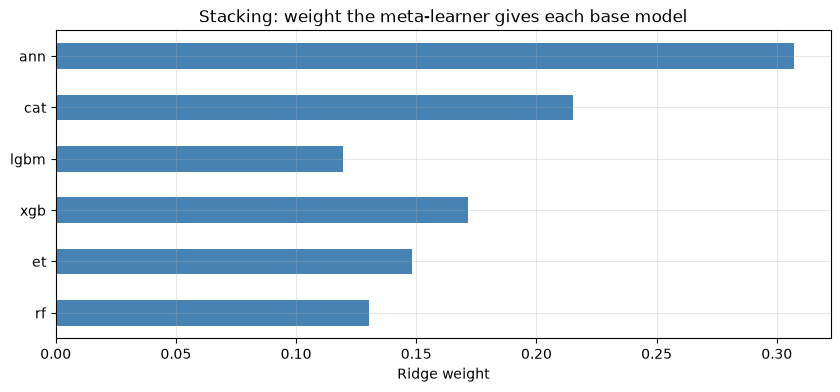

rf      0.130
et      0.148
xgb     0.172
lgbm    0.120
cat     0.215
ann     0.307
dtype: float64

In [24]:
w = pd.Series(stack.final_estimator_.coef_, index=[n for n, _ in base_models])
print("meta-learner intercept:", round(stack.final_estimator_.intercept_, 3))
w.plot.barh(color="steelblue"); plt.title("Stacking: weight the meta-learner gives each base model"); plt.xlabel("Ridge weight")
plt.show()
w.round(3)

## 10. Comparison of results (test years 2023-2024)

In [25]:
res_df = pd.DataFrame(results).T
for c in ["RMSE", "MAE", "R2", "RainDay_Acc", "RainDay_F1", "Heavy_MAE", "Fit_sec"]:
    res_df[c] = res_df[c].astype(float)
res_df = res_df.sort_values("RMSE")
res_df.round(3)

,family,RMSE,MAE,R2,RainDay_Acc,RainDay_F1,Heavy_MAE,Fit_sec
Stacking (6 models → Ridge),Stacking,8.081,4.560,0.394,0.767,0.842,21.342,48.983
Hybrid: RF + ANN (average),Hybrid,8.113,4.552,0.390,0.761,0.839,21.782,NaN
Random Forest,Bagging,8.148,4.655,0.384,0.745,0.833,22.094,4.686
Hybrid: ARMA + RF (residuals),Hybrid,8.151,4.639,0.384,0.741,0.831,22.116,5.449
LightGBM,Boosting,8.175,4.703,0.380,0.656,0.792,22.900,0.485
CatBoost,Boosting,8.177,4.652,0.380,0.727,0.824,22.365,0.811
Extra Trees,Bagging,8.180,4.632,0.380,0.740,0.830,22.823,1.841
Bagging (Decision Trees),Bagging,8.189,4.679,0.378,0.747,0.834,21.896,8.802
XGBoost,Boosting,8.214,4.702,0.374,0.704,0.814,23.140,0.264
Linear Regression,Baseline,8.215,4.725,0.374,0.737,0.825,22.811,0.027


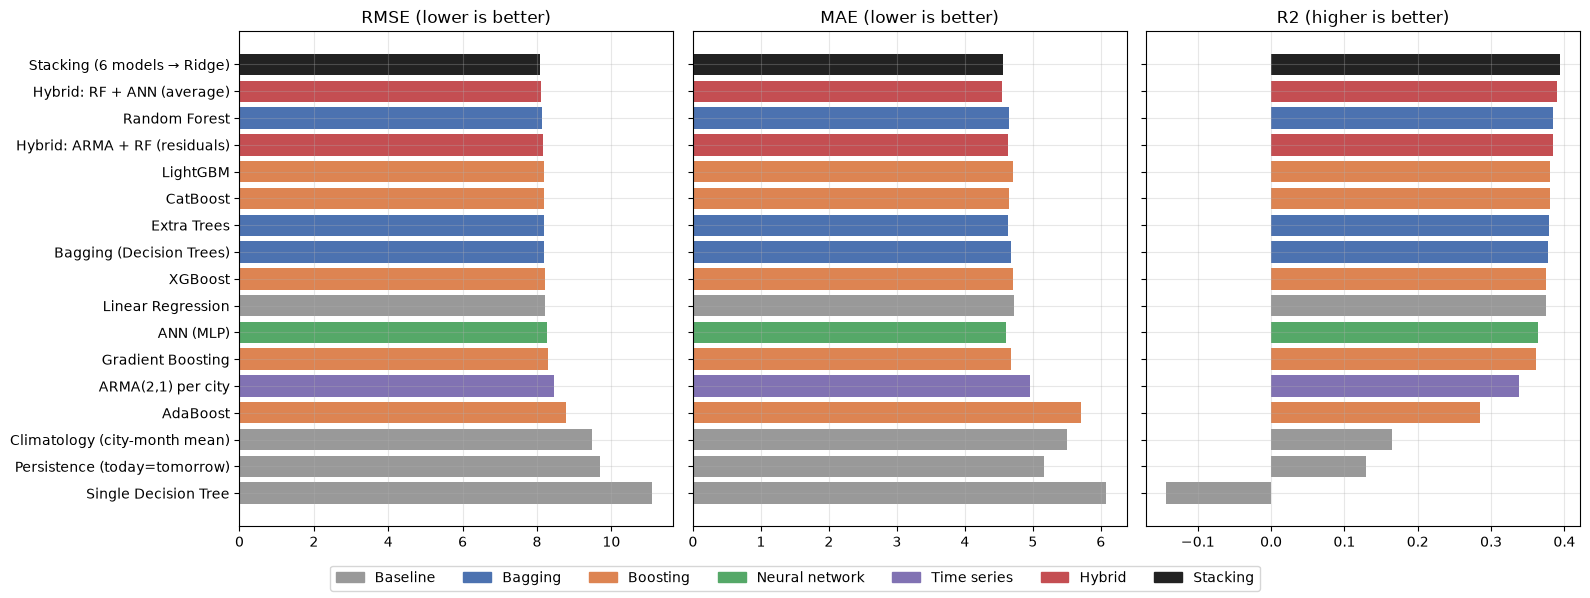

In [26]:
fam_colors = {"Baseline": "#999999", "Bagging": "#4C72B0", "Boosting": "#DD8452", "Neural network": "#55A868",
              "Time series": "#8172B3", "Hybrid": "#C44E52", "Stacking": "#222222"}
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
order = res_df.index[::-1]
for ax, m in zip(axes, ["RMSE", "MAE", "R2"]):
    ax.barh(order, res_df.loc[order, m], color=[fam_colors[f] for f in res_df.loc[order, "family"]])
    ax.set_title(m + (" (higher is better)" if m == "R2" else " (lower is better)"))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_colors.values()]
fig.legend(handles, fam_colors.keys(), loc="lower center", ncol=7)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

### Error by climatic zone and by monsoon season

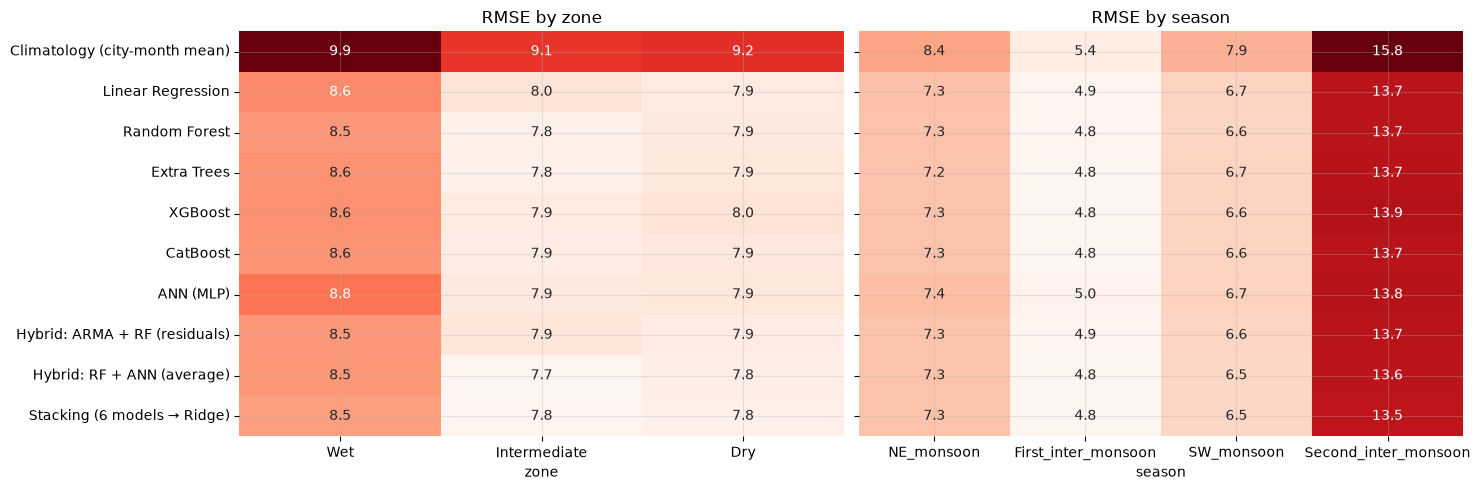

Mean actual rain by zone in the test years (mm/day): {'Dry': 5.0, 'Intermediate': 6.4, 'Wet': 8.1}


In [27]:
show = ["Climatology (city-month mean)", "Linear Regression", "Random Forest", "Extra Trees", "XGBoost", "CatBoost",
        "ANN (MLP)", "Hybrid: ARMA + RF (residuals)", "Hybrid: RF + ANN (average)", "Stacking (6 models → Ridge)"]
def rmse_by(col):
    out = {}
    for m in show:
        e = (test[TARGET] - preds[m]) ** 2
        out[m] = e.groupby(test[col]).mean() ** 0.5
    return pd.DataFrame(out).T
by_zone = rmse_by("zone")[["Wet", "Intermediate", "Dry"]]
by_season = rmse_by("season")[["NE_monsoon", "First_inter_monsoon", "SW_monsoon", "Second_inter_monsoon"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(by_zone, annot=True, fmt=".1f", cmap="Reds", ax=axes[0], cbar=False); axes[0].set_title("RMSE by zone")
sns.heatmap(by_season, annot=True, fmt=".1f", cmap="Reds", ax=axes[1], cbar=False); axes[1].set_title("RMSE by season")
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()
print("Mean actual rain by zone in the test years (mm/day):", test.groupby("zone")[TARGET].mean().round(1).to_dict())

### Predictions vs reality - two monsoon examples

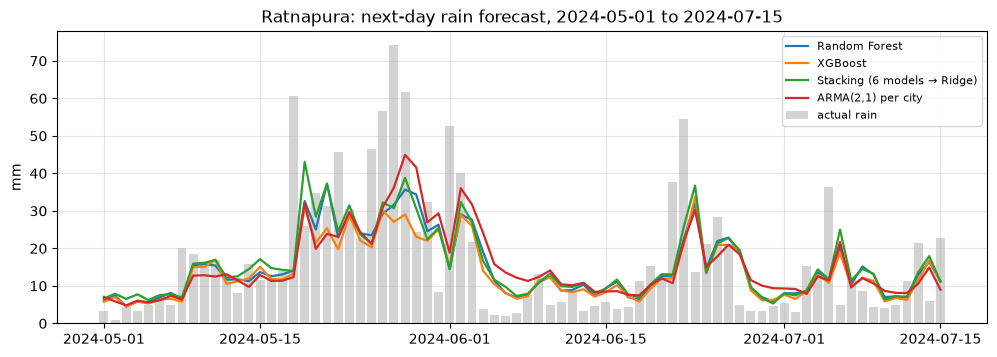

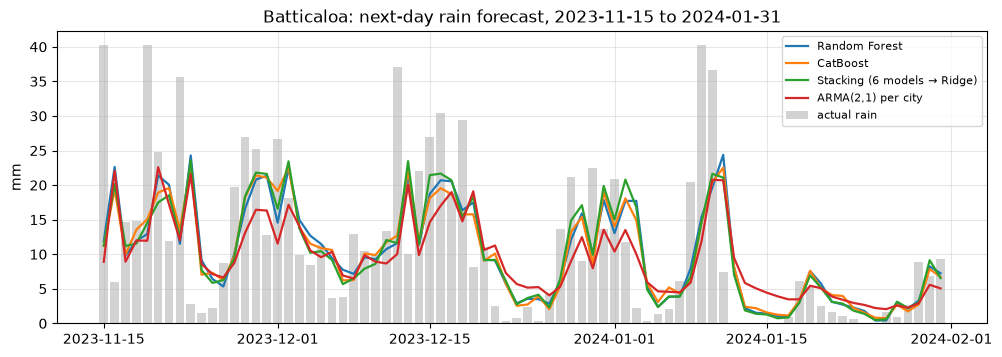

In [28]:
def plot_city(city, start, end, models):
    m = (test.city == city) & (test.target_date >= start) & (test.target_date <= end)
    plt.figure(figsize=(12, 3.8))
    plt.bar(test.loc[m, "target_date"], test.loc[m, TARGET], color="lightgray", label="actual rain")
    for name in models:
        plt.plot(test.loc[m, "target_date"], preds[name][m.values], label=name, lw=1.6)
    plt.ylabel("mm"); plt.title(f"{city}: next-day rain forecast, {start} to {end}"); plt.legend(fontsize=8); plt.show()

plot_city("Ratnapura", "2024-05-01", "2024-07-15", ["Random Forest", "XGBoost", "Stacking (6 models → Ridge)", "ARMA(2,1) per city"])
plot_city("Batticaloa", "2023-11-15", "2024-01-31", ["Random Forest", "CatBoost", "Stacking (6 models → Ridge)", "ARMA(2,1) per city"])

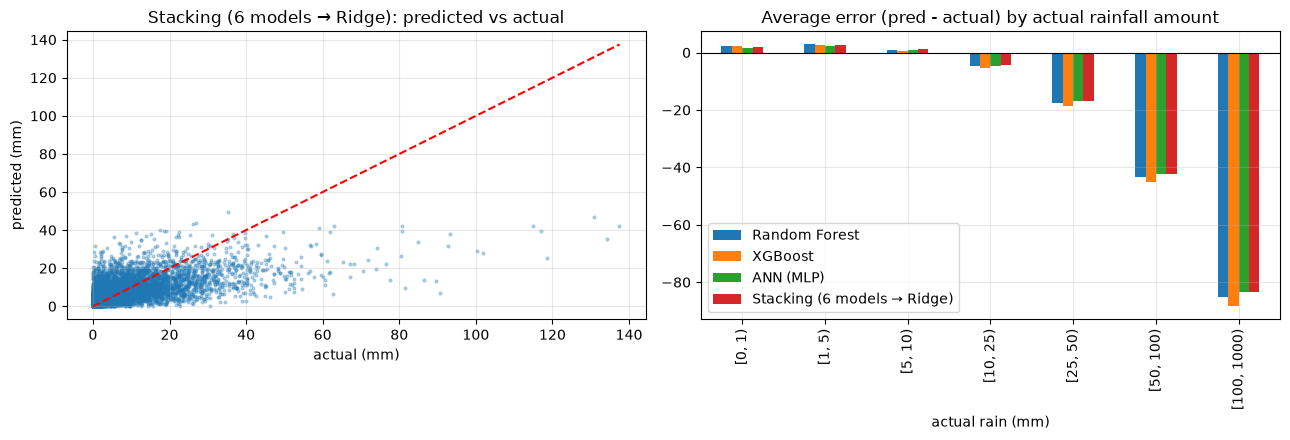

In [29]:
best_name = res_df.index[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_test, preds[best_name], s=4, alpha=0.3)
lim = max(y_test.max(), preds[best_name].max())
axes[0].plot([0, lim], [0, lim], "r--"); axes[0].set_xlabel("actual (mm)"); axes[0].set_ylabel("predicted (mm)")
axes[0].set_title(f"{best_name}: predicted vs actual")
bins = [0, 1, 5, 10, 25, 50, 100, 1000]
grp = pd.cut(y_test, bins, right=False)
bias = pd.DataFrame({m: (pd.Series(preds[m]) - y_test.values).groupby(grp.values, observed=True).mean()
                     for m in ["Random Forest", "XGBoost", "ANN (MLP)", best_name]})
bias.plot.bar(ax=axes[1]); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Average error (pred - actual) by actual rainfall amount"); axes[1].set_xlabel("actual rain (mm)")
plt.tight_layout(); plt.show()

## 11. Interpretation - which features drive the forecasts?

We compare three views of feature importance:
- **Random Forest** - mean decrease in impurity (how much a feature reduces error across all splits).
- **XGBoost** - total gain.
- **Permutation importance on the stacked model** - how much the test RMSE gets worse when one feature is shuffled.
  This is model-agnostic and measured on unseen data, so it is the most trustworthy.

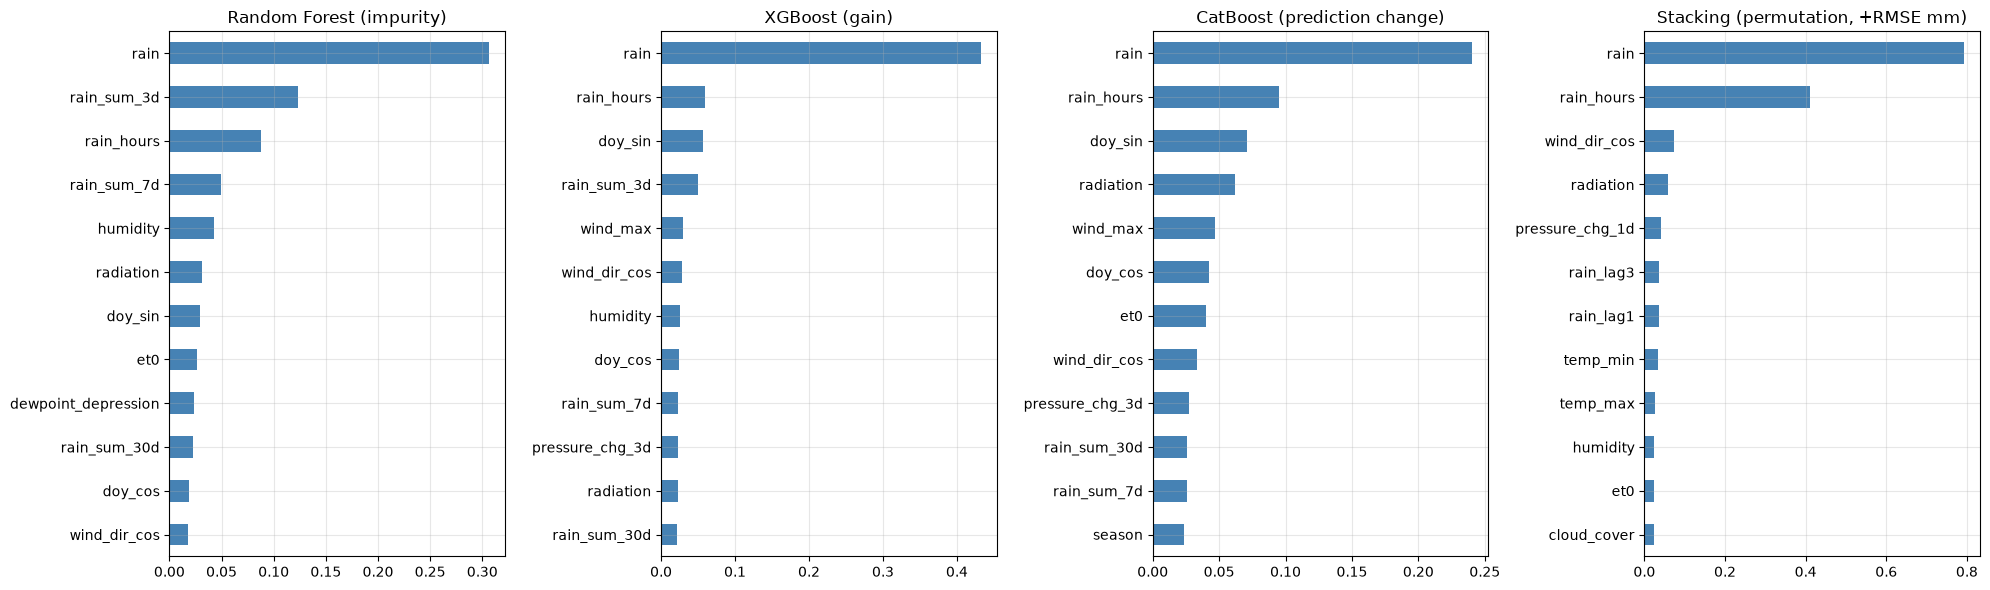

In [30]:
imp_rf = pd.Series(rf.feature_importances_, index=FEATURES)
imp_xgb = pd.Series(xgbm.get_booster().get_score(importance_type="total_gain")).reindex(FEATURES).fillna(0)
imp_xgb = imp_xgb / imp_xgb.sum()
imp_cat = pd.Series(cat.get_feature_importance(), index=CB_FEATURES) / 100

sample = test.sample(4000, random_state=SEED)
perm = permutation_importance(stack, sample[FEATURES], sample[TARGET], n_repeats=3, random_state=SEED,
                              scoring="neg_root_mean_squared_error", n_jobs=1)
imp_stack = pd.Series(perm.importances_mean, index=FEATURES)

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
for ax, (title, s) in zip(axes, [("Random Forest (impurity)", imp_rf), ("XGBoost (gain)", imp_xgb),
                                 ("CatBoost (prediction change)", imp_cat),
                                 ("Stacking (permutation, +RMSE mm)", imp_stack)]):
    s.sort_values().tail(12).plot.barh(ax=ax, color="steelblue"); ax.set_title(title)
plt.tight_layout(); plt.show()

In [31]:
# Which features does each family rely on? Compare RF vs XGBoost ranks
rank = pd.DataFrame({"RF_rank": imp_rf.rank(ascending=False), "XGB_rank": imp_xgb.rank(ascending=False),
                     "Stack_perm_rank": imp_stack.rank(ascending=False)}).astype(int)
rank.sort_values("Stack_perm_rank").head(15)

,RF_rank,XGB_rank,Stack_perm_rank
rain,1,1,1
rain_hours,3,2,2
wind_dir_cos,12,6,3
radiation,6,11,4
pressure_chg_1d,20,16,5
rain_lag3,18,17,6
rain_lag1,21,18,7
temp_min,30,33,8
temp_max,28,25,9
humidity,5,7,10


### Deep-Dive Interpretation: Why Each Model Behaves the Way It Does

In this section, we examine the results table and the charts above to explain why each model family performed the way it did on the 2023 to 2024 Sri Lankan test data.

#### 1. Why a Single Decision Tree Failed ($R^2 = -0.143$, RMSE = $11.10\text{ mm}$) while Bagging Worked (RMSE = $8.15\text{ mm}$)
- **Daily rainfall data is noisy:** Two days in Colombo or Ratnapura can have the same afternoon humidity ($84\%$) and cloud cover ($80\%$), yet one day records $5\text{ mm}$ of rain and the other records $35\text{ mm}$ due to localized rain clouds.
- **Why a single tree overfits:** A single deep decision tree keeps splitting the 2015 to 2022 training data until it memorizes specific heavy rain days. When tested on new days in 2023 and 2024, whenever a day falls into one of those memorized leaves, the tree predicts a large storm. This high variance leads to an RMSE of $11.10\text{ mm}$, which is worse than simply predicting the monthly average every day ($9.49\text{ mm}$), resulting in a negative $R^2$.
- **How Bagging and Random Forest fix this:**
  - **Bagging (`BaggingRegressor`, RMSE = $8.19\text{ mm}$):** Bagging trains $100$ deep trees on different bootstrap samples of the training data and averages their predictions. High and low errors from individual trees cancel out, reducing variance.
  - **Random Forest (`RandomForestRegressor`, RMSE = $8.15\text{ mm}$):** In plain bagging, almost every tree chooses today's rainfall (`rain`) and rain hours (`rain_hours`) at the top split, so the trees make similar errors. Random Forest restricts each split to a random $40\%$ of the features (`max_features=0.4`). That forces many trees to split on humidity, pressure change, wind direction, or solar radiation instead. Because the trees are less correlated, their average is more accurate. In our tree-count chart, the test error drops from $9.44\text{ mm}$ (1 tree) to $8.21\text{ mm}$ (10 trees) and stabilizes at $8.15\text{ mm}$ (200 trees).
  - **Extra Trees (`ExtraTreesRegressor`, RMSE = $8.18\text{ mm}$, MAE = $4.63\text{ mm}$):** Extra Trees also chooses split thresholds at random. This reduces variance further and gives a low MAE ($4.63\text{ mm}$) on normal days, though it slightly under-predicts extreme wet-zone storms.

---

#### 2. Bagging vs. Boosting (Random Forest vs. Gradient Boosting, XGBoost, LightGBM, and CatBoost)
- **Why Boosting can overfit weather data:** Bagging builds trees in parallel, so adding more trees does not cause overfitting. Boosting builds shallow trees one after another, where each new tree fits the residual errors left by the previous trees. In our 1,500-round XGBoost experiment, the training error kept dropping down to $4.35\text{ mm}$, but the test error reached its best point around 80 to 200 rounds and then worsened to $8.39\text{ mm}$. This happens because the largest residuals in daily rainfall data are sudden heavy downpours ($80+\text{ mm}$) that cannot be predicted from daily averages alone. After about 150 trees, boosting starts fitting this random noise.
- **Why Walk-Forward Validation was needed:** To stop the boosted models before they overfit, we evaluated them across three validation years (2020, 2021, and 2022) and picked the tree count with the lowest average validation error (`XGBoost: 83`, `LightGBM: 88`, `CatBoost: 166`, `Gradient Boosting: 96`). With early stopping, all gradient boosted models achieved good test results ($8.18\text{ to }8.21\text{ mm}$ RMSE).
- **Why CatBoost ($8.18\text{ mm}$ RMSE, $4.65\text{ mm}$ MAE) performed best among the boosted models:**
  1. **Balanced (Symmetric) Trees:** CatBoost uses the same feature and split threshold across all nodes at a given depth. This simple structure regularizes the model against extreme rain outliers.
  2. **Built-in Categorical Features (`city`, `zone`, `season`):** CatBoost handles the city name, climatic zone, and monsoon season directly without one-hot encoding, allowing it to learn location and season interactions cleanly.
- **Why AdaBoost had the highest overall RMSE ($8.79\text{ mm}$) but the best Heavy-Rain MAE ($18.49\text{ mm}$):** After each round, AdaBoost assigns higher weight to the samples with the largest errors. Because heavy storms have the largest errors in millimeters, AdaBoost shifts its focus toward extreme rain days. As a result, it over-predicts rain on normal dry days (hurting its overall RMSE and MAE), but produces the most accurate predictions on days when heavy rain ($\ge 25\text{ mm}$) actually occurs.

---

#### 3. Why Time-Series ARMA Alone Is Not Enough (RMSE = $8.45\text{ mm}$) and How `ARMA + Random Forest` Fixes It (RMSE = $8.15\text{ mm}$)
- **What ARMA(2,1) captures:** Looking at the fitted ARMA table across all 12 cities, every city has a positive lag-1 weight ($\text{ar.L1} \approx 1.13\text{ to }1.35$) and a baseline constant that matches its climate ($10.72\text{ mm}$ in wet-zone Ratnapura vs. $3.08\text{ mm}$ in dry-zone Hambantota). This captures multi-day monsoon rain spells.
- **Why ARMA struggles on its own:** ARMA only uses past rainfall values. It cannot see that today's air pressure dropped (`pressure_chg_1d`), that cloud cover is at $95\%$, or that the wind shifted to the south-west. Because of that, its forecast is one day late whenever a new rainy spell begins.
- **Why the Hybrid (`ARMA + RF on residuals`) works:** In the hybrid model, ARMA produces the baseline time-series forecast, and a Random Forest predicts the leftover ARMA residual using all the weather variables (humidity, clouds, wind direction, pressure change, and radiation). Combining them lowered the RMSE from $8.45\text{ mm}$ to **$8.15\text{ mm}$** and raised the Rain-Day F1 score from $0.795$ to $0.831$.

---

#### 4. Why Combining Trees with a Neural Network (`RF + ANN` and `Stacking`) Gives the Best Forecast
- **Tree models vs. Neural Networks:**
  - Decision trees split features using step-function thresholds (for example, `rain_hours > 6` and `zone == Wet`).
  - Our neural network (`ANN (MLP)` with two hidden layers of 64 and 32 neurons) fits a smooth, continuous function across the standardized inputs. Even though the ANN on its own had a slightly higher RMSE ($8.28\text{ mm}$), it achieved a **better MAE ($4.60\text{ mm}$), a better Rain-Day F1 ($0.839$), and a better Heavy-Rain MAE ($21.64\text{ mm}$)** than any individual tree model.
- **Why `RF + ANN` ($8.11\text{ mm}$ RMSE, $4.55\text{ mm}$ MAE) beats both models alone:** Because a tree ensemble and a neural network make different types of errors, averaging their predictions reduces variance and beats both Random Forest ($8.15\text{ mm}$) and the ANN ($8.28\text{ mm}$).
- **Why `Stacking (6 models -> Ridge)` ranked first overall (RMSE = $8.081\text{ mm}$, $R^2 = 0.394$, Rain-Day F1 = $0.842$, Heavy-Rain MAE = $21.34\text{ mm}$):**
  - Instead of a fixed 50/50 average, Stacking uses a Ridge Regression meta-learner trained on 5-fold out-of-fold predictions to weight each base model:
    $$\hat{y}_{\text{stack}} = -0.412 + 0.307\,\hat{y}_{\text{ANN}} + 0.215\,\hat{y}_{\text{CatBoost}} + 0.172\,\hat{y}_{\text{XGBoost}} + 0.148\,\hat{y}_{\text{ExtraTrees}} + 0.130\,\hat{y}_{\text{RF}} + 0.120\,\hat{y}_{\text{LightGBM}}$$
  - The meta-learner assigns positive weight to **all three model families**: about **$31\%$ to the Neural Network**, **$51\%$ across the three Boosting models** (CatBoost, XGBoost, LightGBM), and **$28\%$ across the two Bagging models** (Extra Trees, Random Forest), plus a small negative intercept ($-0.41\text{ mm}$) that trims small false rain predictions on dry days.
  - Because it combines all three paradigms, Stacking achieved the lowest RMSE in **every climatic zone** (Wet: $8.48\text{ mm}$, Intermediate: $7.75\text{ mm}$, Dry: $7.80\text{ mm}$) and during the **Second Inter-Monsoon in October and November** ($13.52\text{ mm}$ vs. $15.79\text{ mm}$ for climatology).

---

#### 5. What the Feature Importance and Error Charts Show About Sri Lankan Weather
- **Top weather drivers:** Across Random Forest, XGBoost, and permutation importance on the Stacked model, four physical signals drive tomorrow's rainfall:
  1. **Recent rainfall persistence (`rain`, `rain_hours`, `rain_lag1`, `rain_lag3`):** Monsoon systems and low-pressure troughs typically last several days.
  2. **Monsoon wind direction (`wind_dir_cos`, `wind_dir_sin`, ranked #3 in Stacking permutation importance):** Wind direction separates moist south-west monsoon flow off the Indian Ocean (hitting Colombo, Galle, and Ratnapura) from north-east monsoon flow off the Bay of Bengal (hitting Trincomalee, Batticaloa, and Jaffna).
  3. **Solar radiation, temperature, and cloud cover (`radiation`, `temp_max`, `temp_min`, `et0`, `cloud_cover`):** High solar radiation and high evapotranspiration indicate clear, dry air, while heavy cloud cover and lower daytime maximum temperatures indicate active monsoon conditions.
  4. **24-hour pressure change (`pressure_chg_1d`, ranked #5 in Stacking):** A drop in sea-level air pressure over 24 hours indicates an approaching low-pressure trough or depression.
- **Why all models under-predict extreme rain ($\ge 50\text{ mm}$):** In the error-by-rainfall chart (Section 10), all models predict slightly too high on dry days ($+1\text{ to }+2\text{ mm}$) and too low on extreme storm days ($\ge 50\text{ mm}$). Because the models minimize squared error (RMSE), they predict the conditional average for a given set of weather readings. Since most rainy days are moderate ($5\text{ to }20\text{ mm}$) and $50+\text{ mm}$ storms are rare (skewness $= 5.8$), the expected value from surface station readings alone stays in the moderate range.

## 12. Save models and results for the dashboard

The dashboard (`app.py`) loads these pickle files. Models are saved with `joblib` (compressed) so the repository stays
small enough for GitHub and Streamlit Community Cloud.

In [32]:
to_save = {"random_forest": rf, "extra_trees": et, "bagging": bag, "gradient_boosting": gbr, "xgboost": xgbm,
           "lightgbm": lgbm, "catboost": cat, "ann": ann, "stacking": stack, "arma_rf_residual": rf_resid,
           "linear_regression": lin}
for name, m in to_save.items():
    joblib.dump(m, f"models/{name}.pkl", compress=3)
joblib.dump({"arma_params": arma_models, "order": (2, 0, 1)}, "models/arma_params.pkl")
json.dump({"FEATURES": FEATURES, "CB_FEATURES": CB_FEATURES, "CAT_FEATURES": CAT_FEATURES,
           "BASE_FEATURES": BASE_FEATURES, "TARGET": TARGET}, open("models/feature_config.json", "w"), indent=2)

res_df.to_csv("results/metrics.csv")
by_zone.to_csv("results/rmse_by_zone.csv"); by_season.to_csv("results/rmse_by_season.csv")
pd.DataFrame({"random_forest": imp_rf, "xgboost": imp_xgb, "stacking_permutation": imp_stack}).to_csv("results/feature_importance.csv")
w.to_csv("results/stacking_weights.csv", header=["weight"])
pd.DataFrame({"trees": ks, "rmse": rmse_k}).to_csv("results/rf_trees_curve.csv", index=False)
pd.DataFrame({"round": range(len(ev["validation_0"]["rmse"])), "train_rmse": ev["validation_0"]["rmse"],
              "test_rmse": ev["validation_1"]["rmse"]}).to_csv("results/xgb_rounds_curve.csv", index=False)

# test-period features + every model's prediction (used by the "historical day" page of the dashboard)
out = test[["city", "date", "target_date", TARGET, "arma"] + CB_FEATURES[:-3] + ["zone", "season"] + ONEHOT].copy()
out = out.loc[:, ~out.columns.duplicated()]
for name in results:
    out["pred__" + name] = preds[name]
out.to_csv("data/processed/test_predictions.csv", index=False)
raw.assign(month=raw.date.dt.month).groupby(["city", "zone", "month"])["rain"].mean().reset_index().to_csv(
    "data/processed/monthly_climatology.csv", index=False)
city_info.to_csv("data/processed/city_info.csv")

for f in sorted(Path("models").glob("*")):
    print(f"{f.name:<28} {f.stat().st_size / 1e6:6.1f} MB")

ann.pkl                         0.1 MB
arma_params.pkl                 0.0 MB
arma_rf_residual.pkl            6.2 MB
bagging.pkl                     4.5 MB
catboost.pkl                    0.1 MB
extra_trees.pkl                12.4 MB
feature_config.json             0.0 MB
gradient_boosting.pkl           0.1 MB
lightgbm.pkl                    0.1 MB
linear_regression.pkl           0.0 MB
random_forest.pkl               8.1 MB
stacking.pkl                   20.9 MB
xgboost.pkl                     0.1 MB


## 13. Conclusion, Limitations, and Future Work

### Key Takeaways
1. **Combining different types of models works best:** Across 43,836 real daily weather records from 12 Sri Lankan cities (2015-2024), our **Stacking Ensemble** (which combines Bagging, Boosting, and a Neural Network with a Ridge meta-learner) gave the most accurate forecasts on the unseen 2023-2024 test years (**RMSE = $8.081\text{ mm}$, R² = $0.394$, Rain-Day F1 = $0.842$, Heavy-Rain MAE = $21.34\text{ mm}$**), followed closely by the **Hybrid Random Forest + ANN** (**RMSE = $8.113\text{ mm}$, MAE = $4.552\text{ mm}$**).
2. **Bagging vs. Boosting on noisy rainfall data:** Bagging models (`Random Forest`: $8.148\text{ mm}$, `Extra Trees`: $8.180\text{ mm}$) do not overfit when we add more trees because averaging deep trees cancels out variance. Boosting models (`LightGBM`: $8.175\text{ mm}$, `CatBoost`: $8.177\text{ mm}$, `XGBoost`: $8.214\text{ mm}$) cut error quickly in the first 80-170 trees, but need walk-forward early stopping so they do not start memorizing random cloudbursts.
3. **Time-Series Hybrid (`ARMA + Random Forest`):** A plain `ARMA(2,1)` time-series model captures multi-day rainy spells (RMSE = $8.448\text{ mm}$) but misses sudden weather changes; training a Random Forest on the ARMA errors using today's weather features brings the RMSE down to **$8.151\text{ mm}$**.

### Limitations and Future Improvements
- **Extreme storm days ($>50\text{ mm/day}$):** Ground-station readings from 24 hours earlier cannot see a fast-moving storm forming out in the Bay of Bengal or the Indian Ocean. Adding satellite cloud imagery or ocean pressure grid data would help catch extreme flood events earlier.
- **Two-step forecast (Dry/Wet + Rain Amount):** Since $37.4\%$ of days in our dataset are dry ($<1\text{ mm}$) and rainy days are heavily skewed, a natural next step is a two-stage model: first predict the chance of rain, and then predict the rainfall amount using a log or Tweedie loss.